# 03 · Temporal observation and candidate metrics

**Synthetic public sample · no states, segmentation or risk scoring.** Inspect day/hour/month patterns and individual histories; candidate metrics use a dataset-relative exclusive cutoff and disclose unverified capture.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src/data/load.py").exists(), "Run from the repository or notebooks directory"
sys.path.insert(0, str(ROOT))
from src.data.load import load_tables, audit_tables
from src.features.attendance import member_metrics
tables = load_tables(ROOT)
m, c = tables["members"], tables["checkins"]


In [2]:
for name in ["day_summary", "hour_summary", "monthly_summary"]:
    print(name)
    display(pd.read_csv(ROOT / f"data/processed/{name}.csv"))

day_summary


,day,events,observed_calendar_days,events_per_calendar_day
0,Monday,299,102,2.931373
1,Tuesday,299,102,2.931373
2,Wednesday,302,102,2.960784
3,Thursday,277,103,2.689320
4,Friday,258,103,2.504854
5,Saturday,272,103,2.640777
6,Sunday,293,102,2.872549


hour_summary


,clock_hour,events
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,66
6,6,237
7,7,249
8,8,155
9,9,86


monthly_summary


,month,exported_events,members_with_exported_events,roster_signups,selected_member_calendar_days,events_per_selected_member_calendar_day,boundary_month
0,2023-01,12,2,44,34,0.352941,True
1,2023-02,31,6,16,86,0.360465,False
2,2023-03,39,8,9,223,0.174888,False
3,2023-04,30,7,7,240,0.125000,False
4,2023-05,62,7,12,248,0.250000,False
5,2023-06,56,7,7,240,0.233333,False
6,2023-07,66,8,8,276,0.239130,False
7,2023-08,55,7,4,279,0.197133,False
8,2023-09,56,11,16,357,0.156863,False
9,2023-10,99,11,13,434,0.228111,False


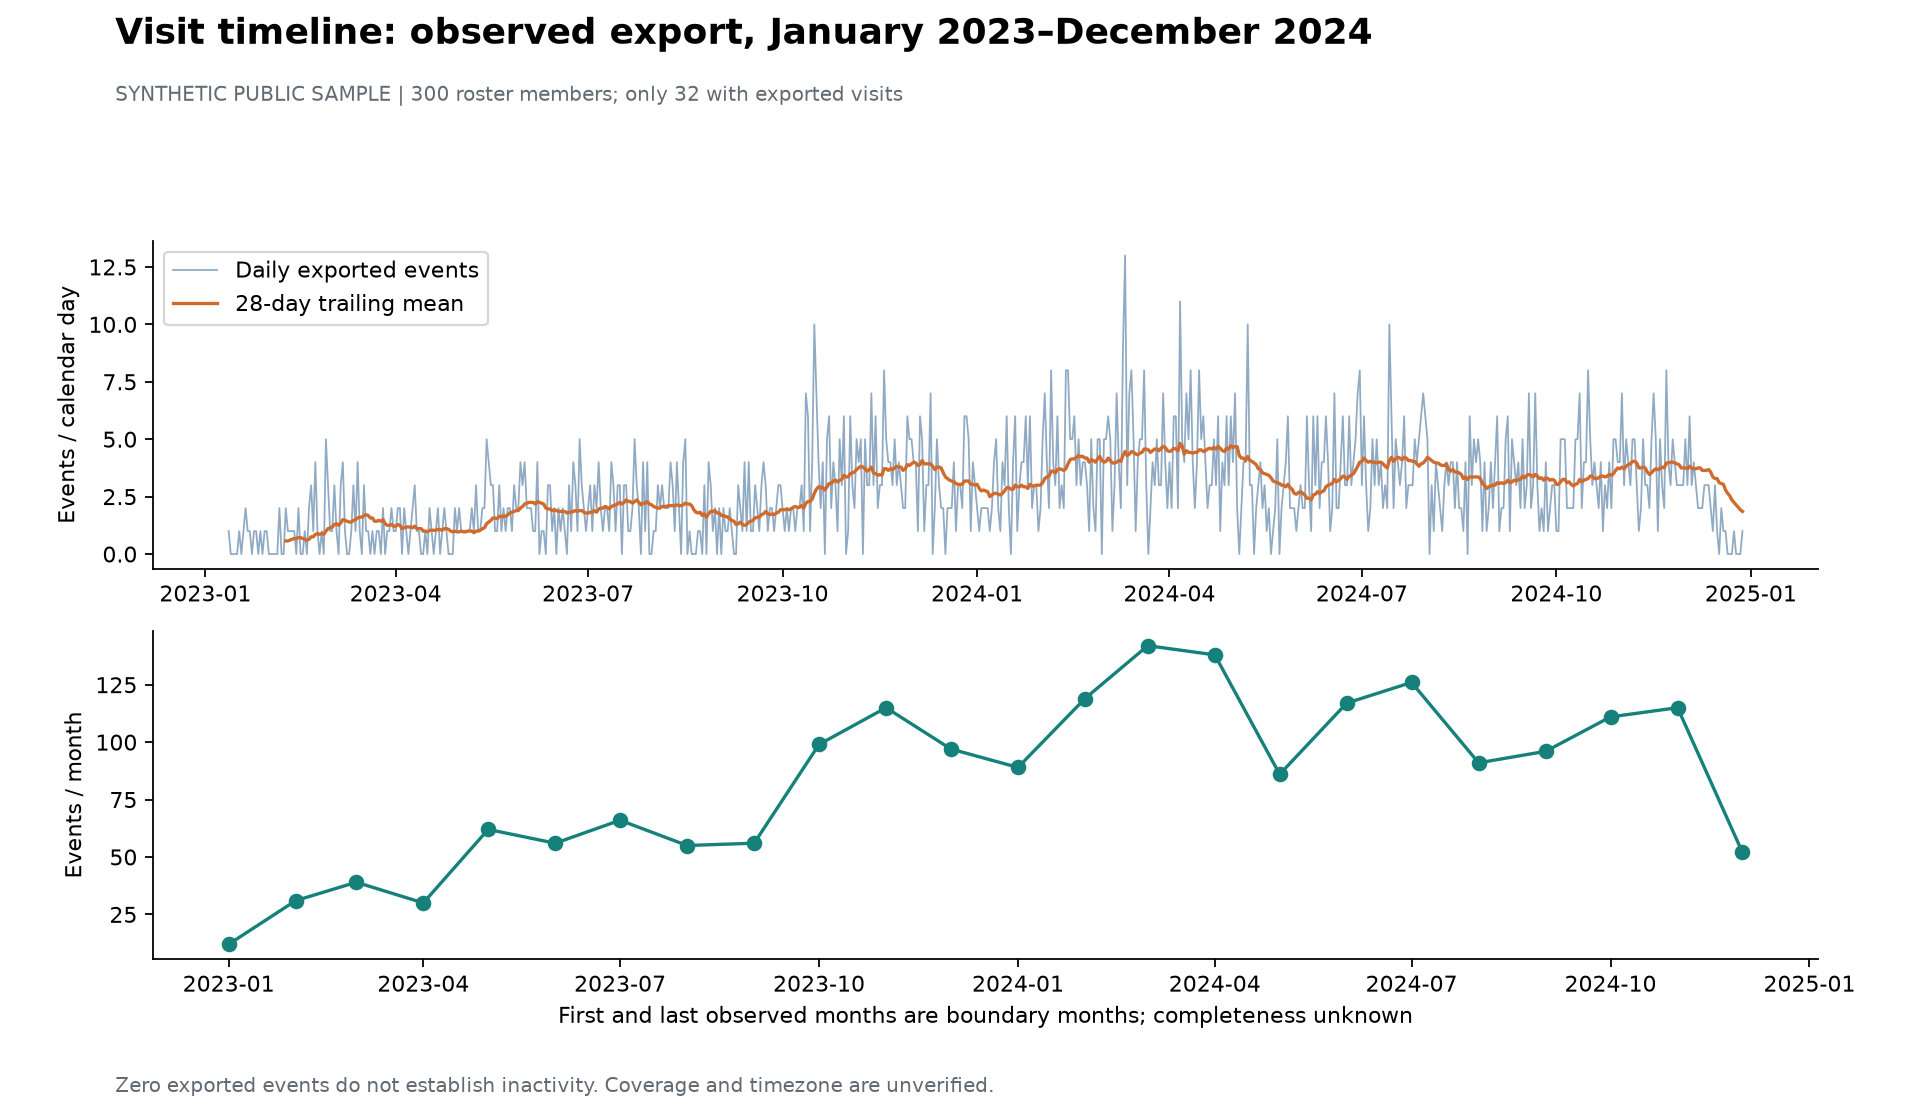

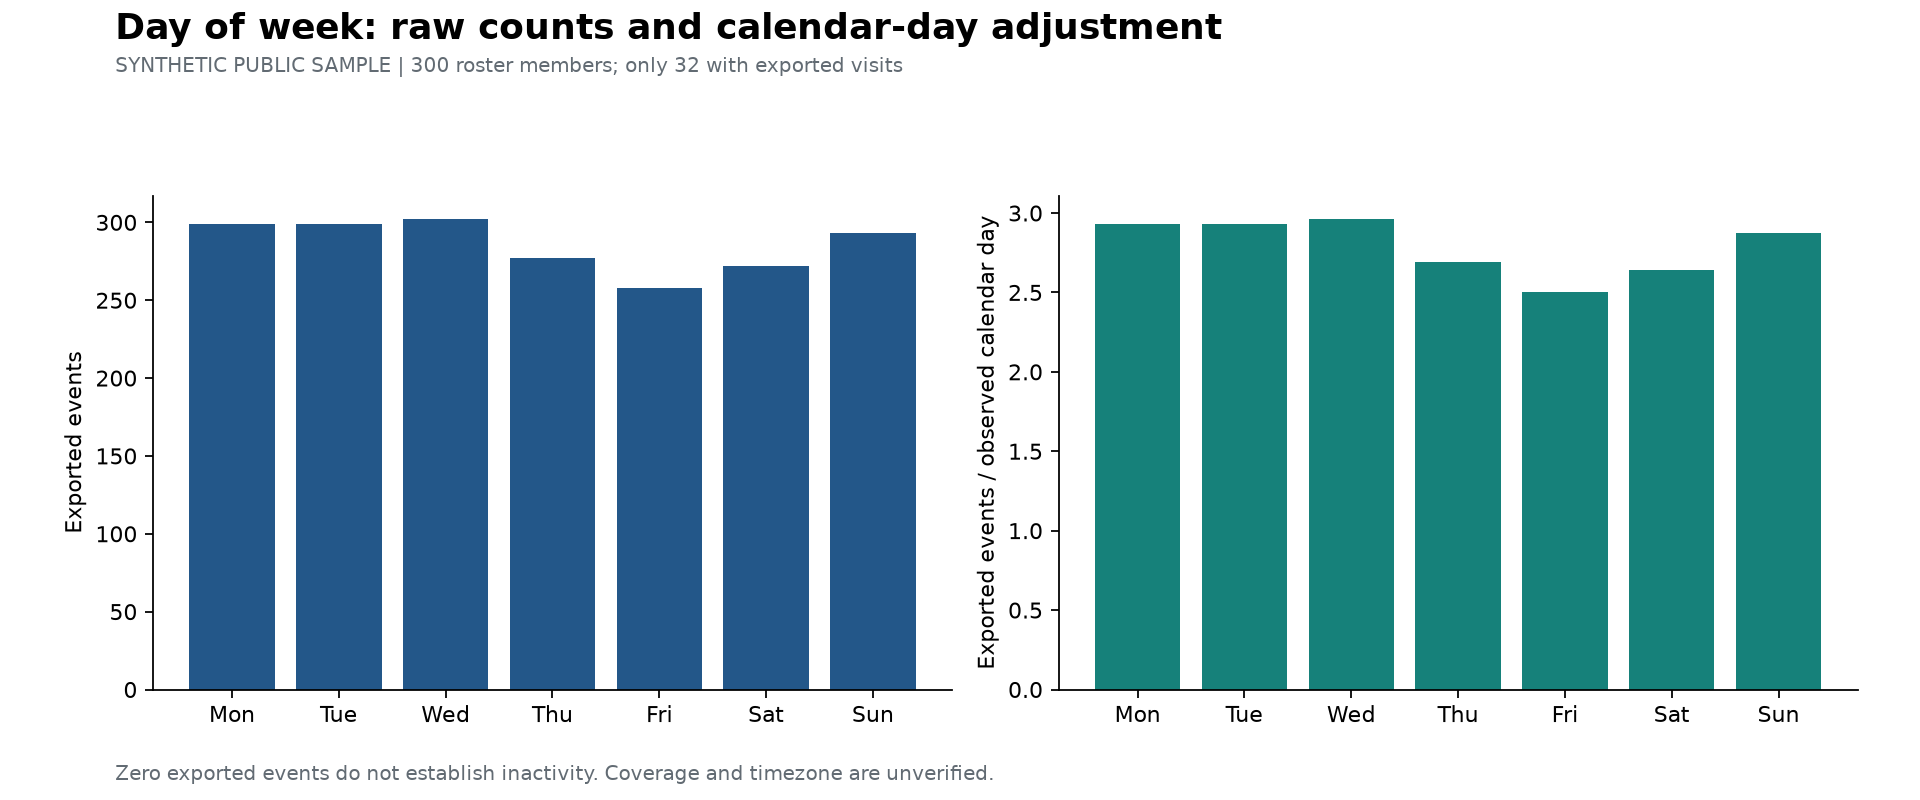

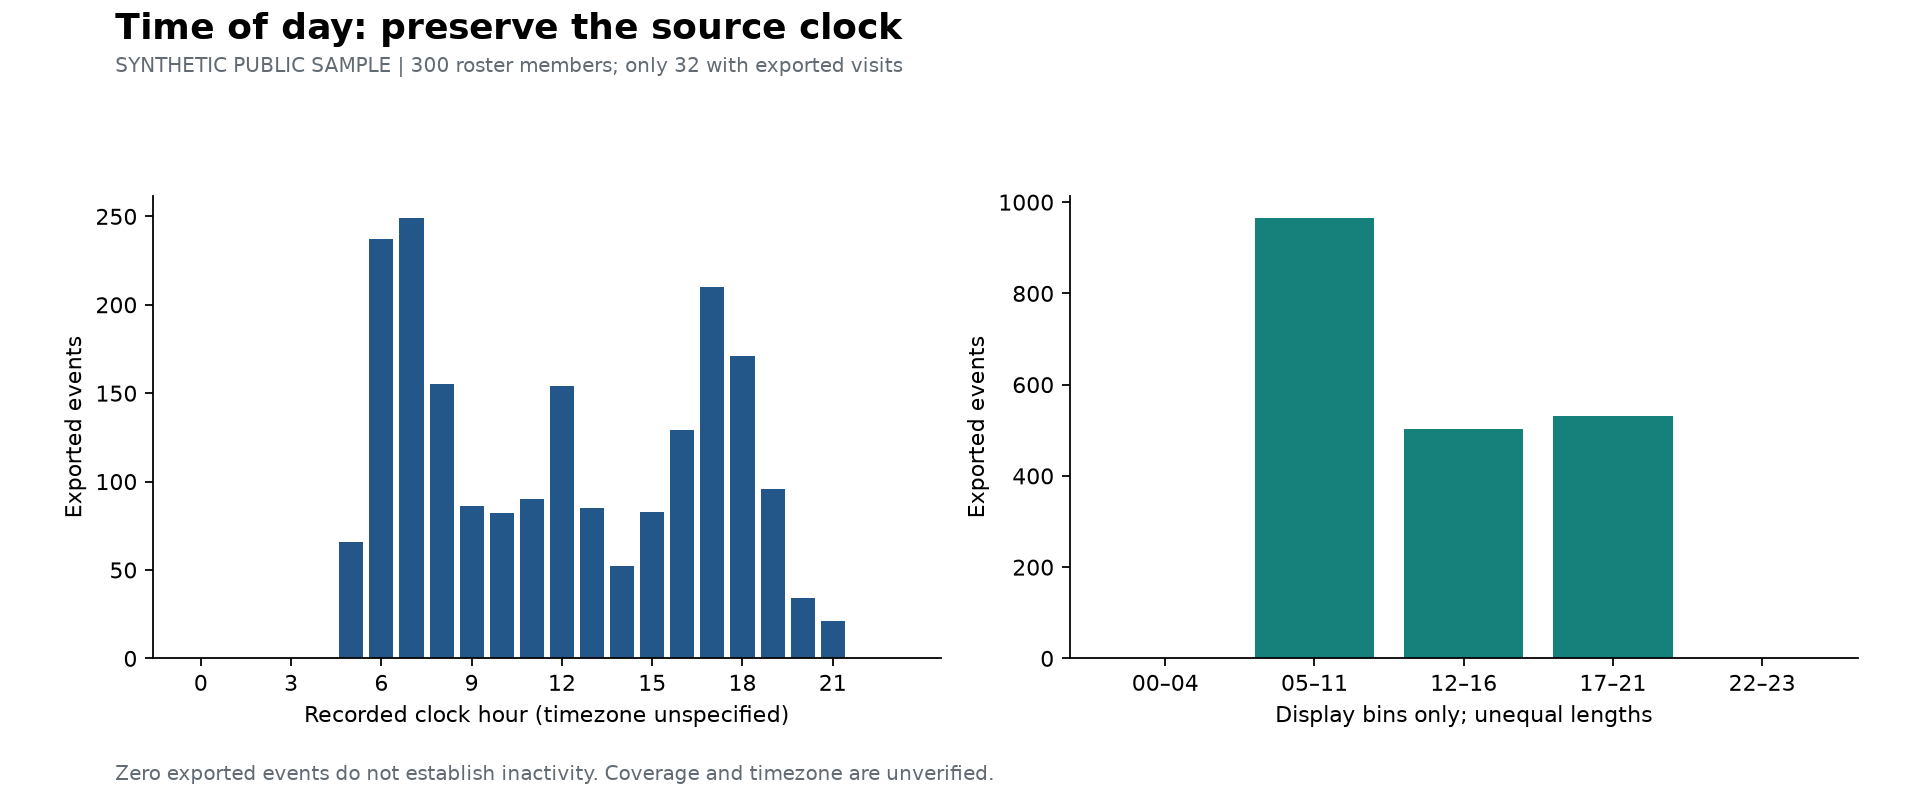

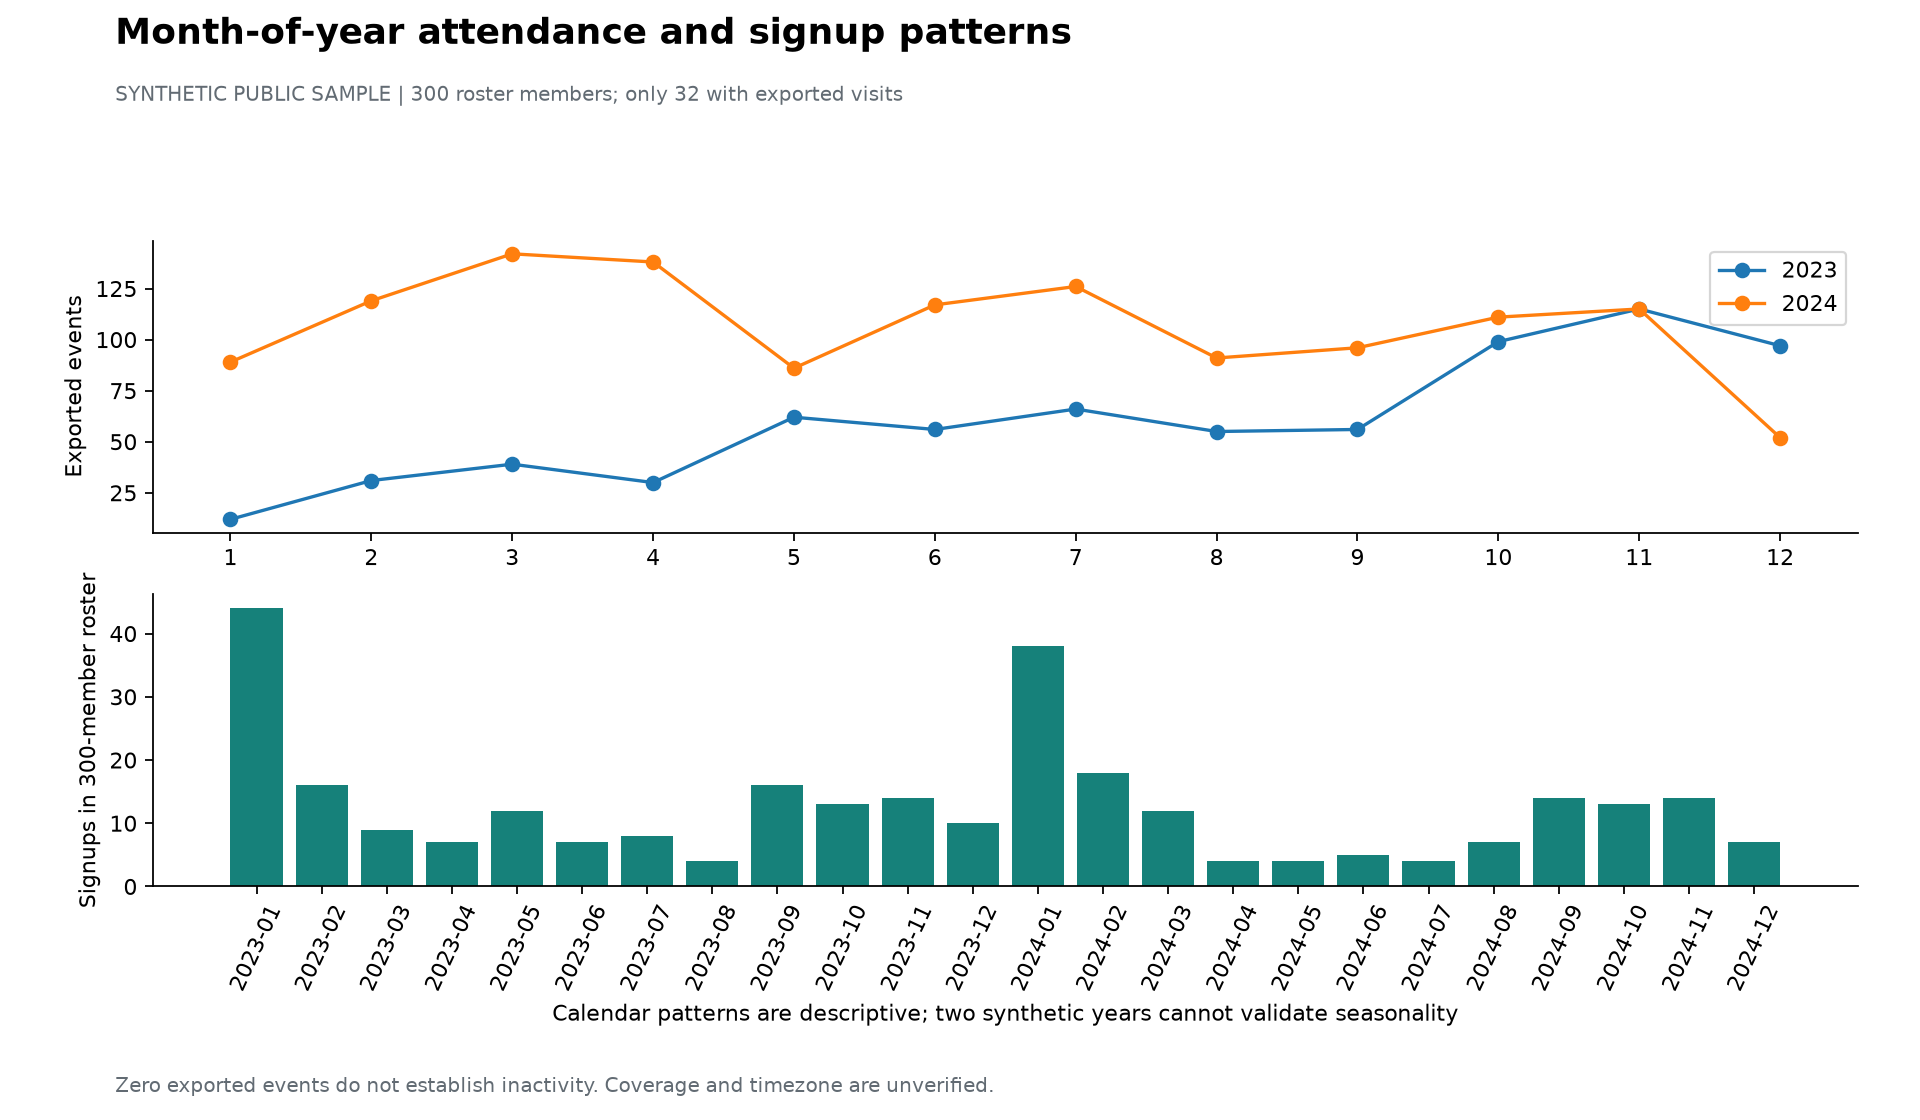

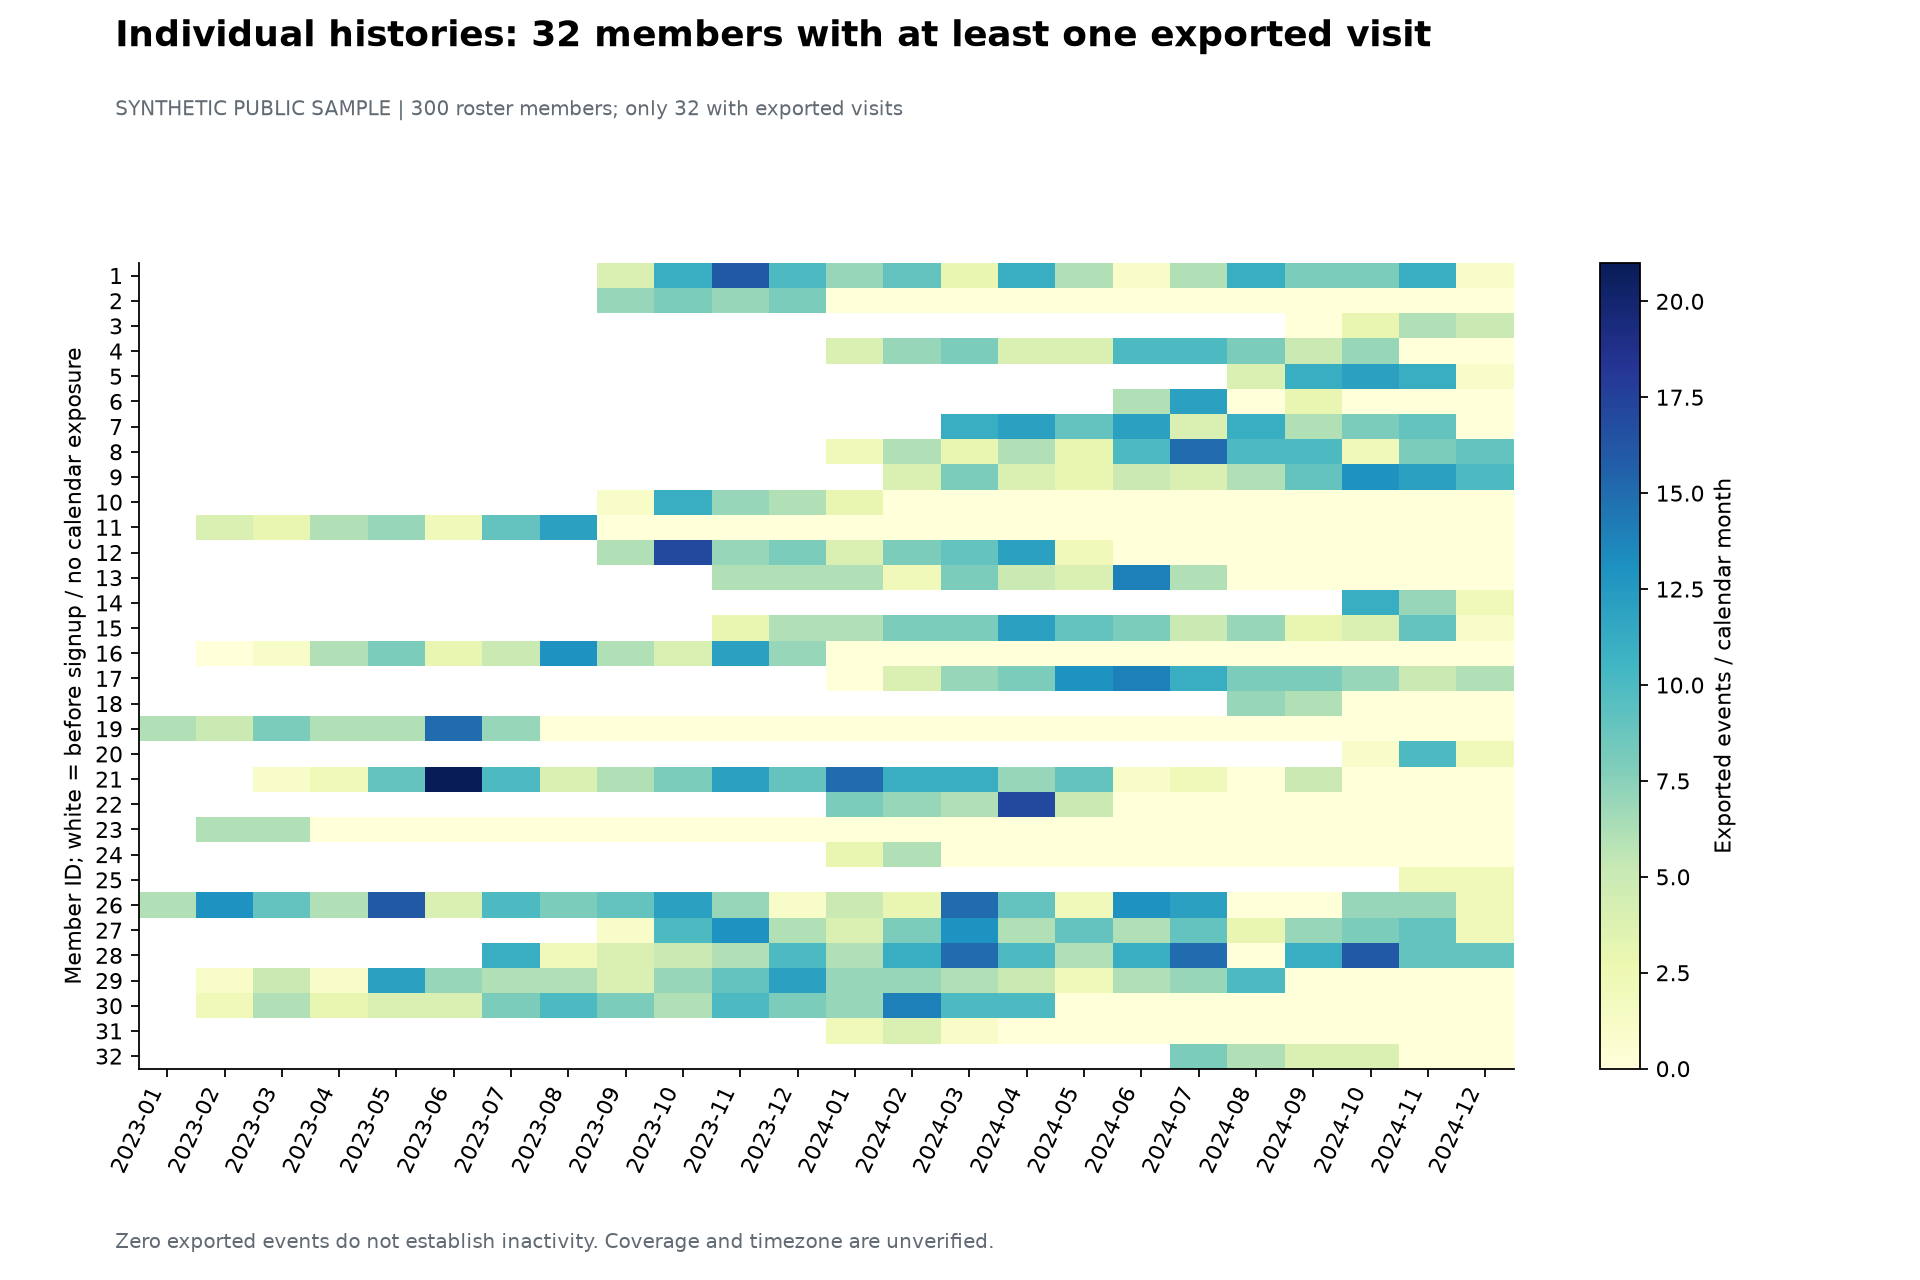

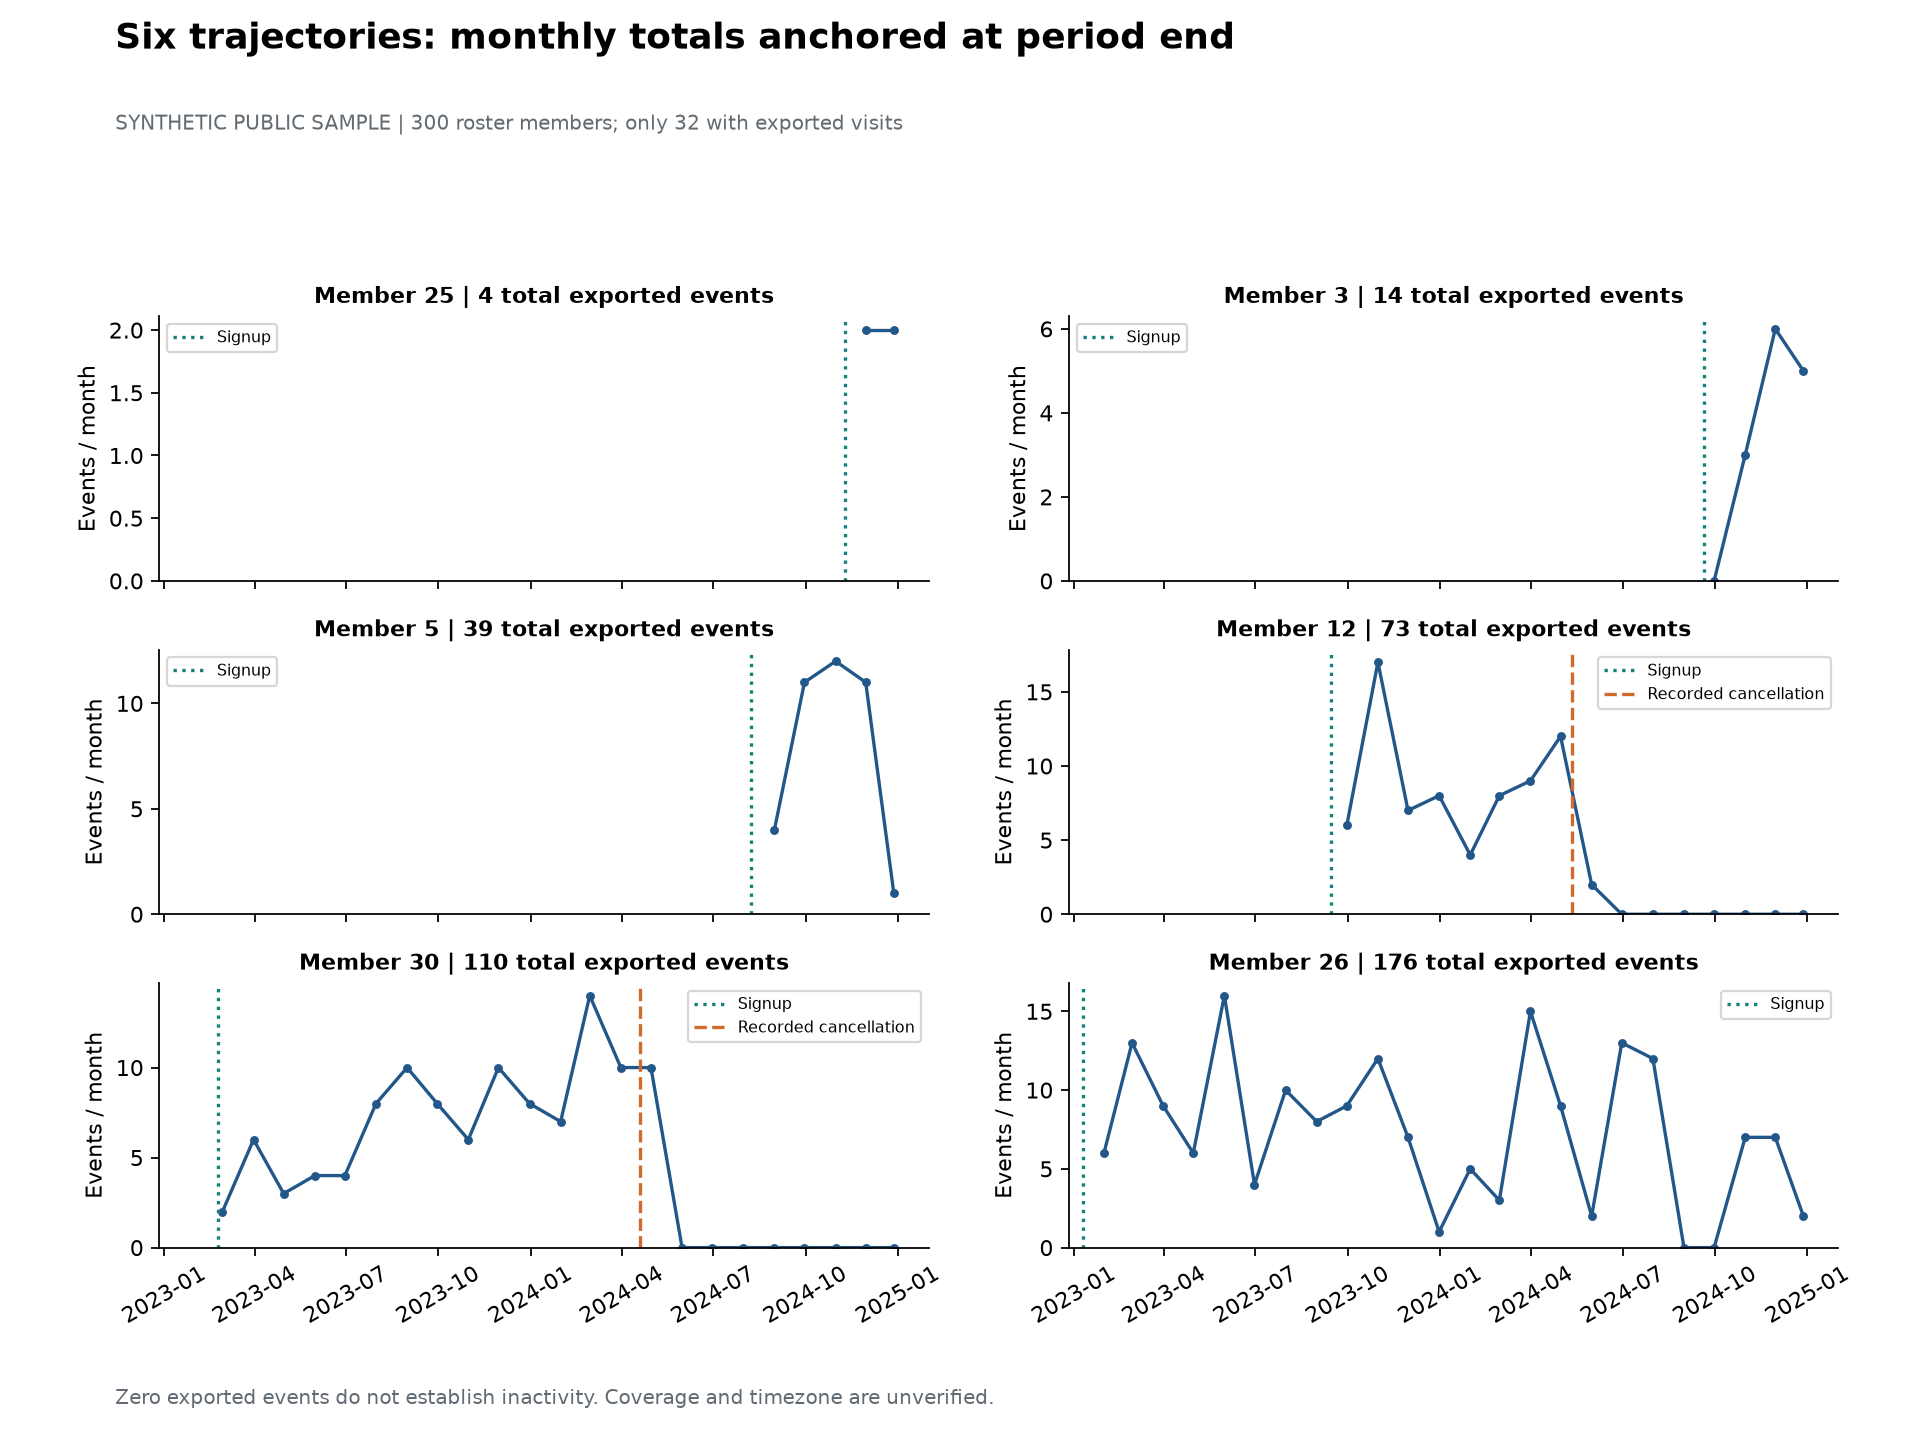

In [3]:
for name in ["02_visit_timeline", "04_day_preference", "05_time_preference", "08_monthly_patterns", "09_member_month_heatmap", "10_individual_trajectories"]:
    display(Image(filename=str(ROOT / f"reports/figures/{name}.png")))

In [4]:
cutoff = c.checkin_datetime.max().normalize() + pd.Timedelta(days=1)
features = member_metrics(m, c, cutoff)
print("Exclusive cutoff", cutoff, "timezone unspecified")
display(features.head())
display(features.sample_observation_status.value_counts().to_frame())
unknown = features.sample_observation_status.eq("no_visits_in_public_sample")
assert features.loc[unknown, "visits_30d"].isna().all()
assert not features.coverage_verified.any()
display(pd.read_csv(ROOT / "handoff/feature_catalog.csv"))

Exclusive cutoff 2024-12-29 00:00:00 timezone unspecified


,member_id,as_of_exclusive,synthetic,coverage_verified,sample_observation_status,membership_tenure_days,first_observed_visit,last_observed_visit,days_since_last_visit,visits_7d,...,attendance_pct_change_30_vs_previous30,attendance_change_30_vs_90_baseline,consistency_window_start,consistency_window_end_exclusive,active_weeks_8w,attendance_variability,preferred_day,preferred_time,branch_diversity,preference_visit_support_90d
0,1,2024-12-29,True,False,visits_present_coverage_unverified,473,2023-09-19 13:37:00,2024-12-01 08:59:00,28.0,0.0,...,-0.916667,-8.5,2024-10-28,2024-12-23,5.0,1.479020,Thursday|Tuesday,morning_05_12,1.0,20.0
1,2,2024-12-29,True,False,visits_present_coverage_unverified,484,2023-09-06 07:06:00,2023-12-30 09:32:00,365.0,0.0,...,NaN,0.0,2024-10-28,2024-12-23,0.0,0.000000,NaN,NaN,0.0,0.0
2,3,2024-12-29,True,False,visits_present_coverage_unverified,100,2024-10-05 18:27:00,2024-12-14 07:42:00,15.0,0.0,...,0.000000,2.0,2024-10-28,2024-12-23,6.0,1.322876,Tuesday,morning_05_12,1.0,14.0
3,4,2024-12-29,True,False,visits_present_coverage_unverified,350,2024-01-15 18:47:00,2024-10-28 15:57:00,62.0,0.0,...,NaN,-3.5,2024-10-28,2024-12-23,1.0,0.330719,Monday,evening_17_22,1.0,7.0
4,5,2024-12-29,True,False,visits_present_coverage_unverified,143,2024-08-09 07:52:00,2024-12-01 20:25:00,28.0,0.0,...,-0.916667,-11.0,2024-10-28,2024-12-23,5.0,1.639360,Sunday,evening_17_22,1.0,25.0


,count
sample_observation_status,
no_visits_in_public_sample,268
visits_present_coverage_unverified,32


,feature,definition,business_meaning,calculation_window,data_requirements,limitations,unit,status
0,visits_7d,Count exported events where C-7 days <= timest...,Recent attendance volume,Trailing 7 calendar days,member_id; visit_timestamp; explicit C; roster...,Synthetic selected sample; capture unverified....,events,implemented_exploratory
1,full_tenure_7d,membership_tenure_days >= 7,Window has full signup-based calendar opportunity,"Signup to C, tested against 7 days",signup_date; C,Calendar tenure does not establish complete ca...,boolean,implemented_exploratory
2,visits_30d,Count exported events where C-30 days <= times...,Recent attendance volume,Trailing 30 calendar days,member_id; visit_timestamp; explicit C; roster...,Synthetic selected sample; capture unverified....,events,implemented_exploratory
3,full_tenure_30d,membership_tenure_days >= 30,Window has full signup-based calendar opportunity,"Signup to C, tested against 30 days",signup_date; C,Calendar tenure does not establish complete ca...,boolean,implemented_exploratory
4,visits_90d,Count exported events where C-90 days <= times...,Recent attendance volume,Trailing 90 calendar days,member_id; visit_timestamp; explicit C; roster...,Synthetic selected sample; capture unverified....,events,implemented_exploratory
5,full_tenure_90d,membership_tenure_days >= 90,Window has full signup-based calendar opportunity,"Signup to C, tested against 90 days",signup_date; C,Calendar tenure does not establish complete ca...,boolean,implemented_exploratory
6,attendance_frequency_30d,visits_30d / 30 * 7; null when tenure < 30,Nominal exported attendance per week,Trailing 30 days,member_id; visit_timestamp; signup_date; C,Synthetic selected sample; capture unverified....,events_per_nominal_week,implemented_exploratory
7,attendance_frequency_90d,visits_90d / 90 * 7; null when tenure < 90,Nominal exported attendance per week,Trailing 90 days,member_id; visit_timestamp; signup_date; C,Synthetic selected sample; capture unverified....,events_per_nominal_week,implemented_exploratory
8,visits_previous30d,"Count events in [C-60d,C-30d)",Prior comparison volume,Previous non-overlapping 30 days,member_id; visit_timestamp; C,Synthetic selected sample; capture unverified....,events,implemented_exploratory
9,attendance_change_30_vs_previous30,visits_30d - visits_previous30d; null if tenur...,Absolute within-member volume change,Current 30 vs previous 30 days,visit_timestamp; member_id; signup_date; C,Synthetic selected sample; capture unverified....,event_difference,implemented_exploratory


## Proposed Phase 2

Verify event capture, timezone, entitlement and operating calendars. Examine recency, frequency, trend and consistency jointly with tenure; compare within-member trajectories; calibrate candidate rules against distributions and operational review before state definitions. Synthetic monthly curves cannot prove January/summer or closure/promotion effects. Behavioral risk would not be contractual churn probability. Secondary datasets must test methods independently, never row-merge members.